In [ ]:
import sys, os
# print(sys.executable()) # confirms which environment/kernel is active
print(os.getcwd())      # confirms current working folder
venv_site_packages = r"C:\Users\vttha\OneDrive\Desktop\deep learning\virtual\Lib\site-packages"

# Insert the virtual environment path at the top of the system path
sys.path.insert(0, venv_site_packages)

# Verify it was added
print(sys.path[0])

In [11]:
from fastbook import *


In [21]:
urls=search_images_ddg('birdphotos',max_images=1)
len(urls),urls[0]     # this is the web scraping used to get image form duck go but not work in today time 

KeyboardInterrupt: 

In [34]:
urls=[]
urls.append("https://img.magnific.com/free-psd/stunning-blackheaded-grosbeak-flight_191095-77874.jpg?semt=ais_hybrid&w=740&q=80")
urls.append("https://static.vecteezy.com/system/resources/thumbnails/049/142/206/small/a-delicate-bird-perched-on-a-blooming-cherry-blossom-branch-capturing-the-essence-of-spring-against-a-soft-serene-background-photo.jpeg")
urls.append("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTE-CLr7EK1AFNuLXRJpWrJSJxDN5xfcOdycZ_6wNF3lA&s")
urls.append("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQMGaSosLVCOy66qxFNF34R7KXvenO2N4uwBAoNVHBexk08-BMDuANlO8XK&s=10")
urls.append("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSlPB6ZBLwXLqmwGUsJRynV7fNGQusWQcrN_XpjWanlL4BXgPE02kbjmpM&s=10")


In [46]:
from pathlib import Path
from fastdownload import download_url
dest_folder = Path("images/bird")
dest_folder.mkdir(parents=True, exist_ok=True) 
for i in range(0,5):
    dest=Path(f"image/bird{i}.jpg")

    if not dest.exists():download_url(urls[i], dest, show_progress=True) 

<div><progress max="38415" value="40960"></progress> 106.63% [40960/38415 00:00&lt;00:00]</div>

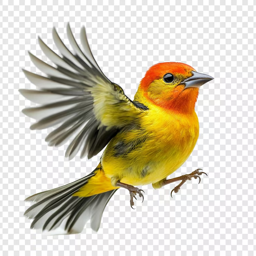

In [4]:
im=Image.open(dest)
im.to_thumb(256,256)

In [78]:
# dls = DataBlock(
#     blocks=(ImageBlock, CategoryBlock),
#     get_items=get_image_files,
#     splitter=RandomSplitter(valid_pct=0.2, seed=42),
#     get_y=parent_label,
#     item_tfms=[Resize(192, method='squish')]
# ).dataloaders(path)
#id first_training

from fastai.vision.all import *
path = untar_data(URLs.PETS)/'images'
def is_cat(x): return x [0].isupper()
dls =ImageDataLoaders.from_name_func(
path, get_image_files(path), valid_pct=0.2, seed=42, label_func=is_cat, item_tfms=Resize(224))
learn =cnn_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune (2)

# dls.show_batch(max_n=5)

<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 15:15&lt;00:00]</div>

c:\Users\vttha\OneDrive\Desktop\deep learning\virtual\Lib\site-packages\fastai\vision\learner.py:304: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to C:\Users\vttha/.cache\torch\hub\checkpoints\resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:10<00:00, 8.35MB/s]


epoch,train_loss,valid_loss,error_rate,time


KeyboardInterrupt: 

In [74]:
dls.show_results()

TypeError: TfmdDL.show_results() missing 2 required positional arguments: 'b' and 'out'

In [73]:
dls.show_batch(max_n=5)

ValueError: This DataLoader does not contain any batches

In [67]:
from fastai.vision.all import verify_images

failed = verify_images(get_image_files(path))
print(failed)
failed.map(Path.unlink)   # deletes the bad ones

KeyboardInterrupt: 

In [65]:
path = Path("./image")
print(path.ls())

[Path('image/bird0.jpg'), Path('image/bird1.jpg'), Path('image/bird2.jpg'), Path('image/bird3.jpg'), Path('image/bird4.jpg')]


In [8]:
learn=cnn_learner(dls,resnet,matrics=error_rate)
learn.fine_tune(3)

NameError: name 'dls' is not defined